<a href="https://colab.research.google.com/github/yvn2000/NLP_CW1/blob/main/material/F21NL_CW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data download

In [1]:
!wget -O wikitext-filtered-full.zip "https://www.dropbox.com/scl/fi/ibd4cmixckghx6hhb361c/wikitext-filtered-full.zip?rlkey=q71cebf0k5fvvwhmcntoswzhq&dl=1"
!wget -O wikitext-filtered-10k.zip "https://www.dropbox.com/scl/fi/ek174r3sg7qjx0aa9atop/wikitext-filtered-10k.zip?rlkey=zy6jqxv6qsc16lr9qm3ki9uhf&dl=1"

--2026-10-18 12:27:06--  https://www.dropbox.com/scl/fi/ibd4cmixckghx6hhb361c/wikitext-filtered-full.zip?rlkey=q71cebf0k5fvvwhmcntoswzhq&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.5.18, 2620:100:601d:18::a27d:512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.5.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc8af8e020d1afdd4acc9296f433.dl-eu.dropboxusercontent.com/cd/0/inline/DKO3mWxpFneEXQtSCyDWuzK56C5wpapk0N9Ah6eUL6u1AOrhfcWkGVae_CleEetciDGN-rkBCEY34D5EOPvoiQhoB1lNSjuuqotFlpFkDKqaaU_iNHXHIJGnlIamw6zfGAnwQYpgP4hNUI_jP5n_XZtD/file?dl=1# [following]
--2026-10-18 12:27:06--  https://uc8af8e020d1afdd4acc9296f433.dl-eu.dropboxusercontent.com/cd/0/inline/DKO3mWxpFneEXQtSCyDWuzK56C5wpapk0N9Ah6eUL6u1AOrhfcWkGVae_CleEetciDGN-rkBCEY34D5EOPvoiQhoB1lNSjuuqotFlpFkDKqaaU_iNHXHIJGnlIamw6zfGAnwQYpgP4hNUI_jP5n_XZtD/file?dl=1
Resolving uc8af8e020d1afdd4acc9296f433.dl-eu.dropboxusercontent.com (uc8af8e020d1afdd4acc9296f433.dl-eu.dropbo

In [2]:
!unzip wikitext-filtered-full.zip
!unzip wikitext-filtered-10k.zip

Archive:  wikitext-filtered-full.zip
   creating: wikitext-filtered-full/
  inflating: wikitext-filtered-full/dataset_info.json  
  inflating: wikitext-filtered-full/state.json  
  inflating: wikitext-filtered-full/data-00000-of-00001.arrow  
Archive:  wikitext-filtered-10k.zip
   creating: wikitext-filtered-10k/
  inflating: wikitext-filtered-10k/dataset_info.json  
  inflating: wikitext-filtered-10k/state.json  
  inflating: wikitext-filtered-10k/data-00000-of-00001.arrow  


In [3]:
!pip install datasets
import datasets

In [4]:
from datasets import load_dataset, Dataset

def load_dataset():
  wikitext_small = "wikitext-filtered-10k"
  wikitext_large = "wikitext-filtered-full"

  dataset_small = Dataset.load_from_disk(wikitext_small)
  dataset_large = Dataset.load_from_disk(wikitext_large)
  print("wikitext_small: {} docs, wikitext_large: {} docs".format(len(dataset_small), len(dataset_large)))
  return dataset_small, dataset_large

wikitext_small, wikitext_large = load_dataset()

print("Type: ", type(wikitext_small))

for i in range(0, 5):
  print("type: ", type(wikitext_small[i]))
  print(wikitext_small[i], "\n")

"""
Access to each text can be obtained using: wikitext_small[0]["text"]
where 0 represents the first one
"""

wikitext_small: 10000 docs, wikitext_large: 859955 docs
Type:  <class 'datasets.arrow_dataset.Dataset'>
type:  <class 'dict'>
{'text': 'Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " .'} 

type:  <class 'dict'>
{'text': "The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it ret

'\nAccess to each text can be obtained using: wikitext_small[0]["text"]\nwhere 0 represents the first one\n'

# Callback: EpochLossLogger

In [5]:
!pip install -q gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 13.6 MB/s eta 0:00:00


In [6]:
from gensim.models.callbacks import CallbackAny2Vec

class EpochLossLogger(CallbackAny2Vec):
    """Callback to log loss after each epoch."""

    def __init__(self):
        self.epoch = 0
        self.prev_loss = 0.0
        self.epoch_losses = []

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        epoch_loss = loss - self.prev_loss

        self.epoch_losses.append(epoch_loss)

        print(
            f"Epoch {self.epoch + 1:02d} | "
            f"epoch loss = {epoch_loss:.2f} | "
            f"cumulative loss = {loss:.2f}"
        )

        self.prev_loss = loss
        self.epoch += 1

loss_logger = EpochLossLogger()


The callback is used as follows:


```
model = Word2Vec(
    ...
    compute_loss = True,
    callbacks=[loss_logger],
    ...
    )
```



In [ ]:
"""
Two Goals:
1. Semantic Relatedness of two words (e.g., how close is the word “doctor” to “nurse”?).
2. Word Analogy (e.g., “apple is to tree as grape is to _ ?”, where the missing word should be “vine”.

Two Main Outputs:
1. Good reporting and discussion of results
2. Some intuitions and (at least a best-effort attempt at an) interpretation of why models behave in certain ways
"""

'\nTwo Goals:\n1. Semantic Relatedness of two words (e.g., how close is the word “doctor” to “nurse”?).\n2. Word Analogy (e.g., “apple is to tree as grape is to _ ?”, where the missing word should be “vine”.\n\nTwo Main Outputs:\n1. Good reporting and discussion of results\n2. Some intuitions and (at least a best-effort attempt at an) interpretation of why models behave in certain ways\n'

In [7]:
"""
STEP 2: TRAIN BASELINES

Using wikitext_small and wikitext_large build two
different word2vec models using the gensim.models.word2vec class from Gensim (the
API can be found here).

Very Important: For each instance of the corpora, you will need to a) tokenize at the empty
space (“ “), b) lowercase every word, and c) remove stopwords1, before attempting to train
anything.
Tip 1: There are several hyperparameters you can set, such as the number of dimensions
(vector_size), the number of iterations (epoch), the context window size (window) and
the minimum number of times each word can appear (min_count). You will get the chance
to experiment with these values more in Step 9, but we recommend for this exercise to use
the following values: vector_size=50, epochs=5, window=5, min_count=5.

Top Tip!!!: Make sure you set workers=8 (or more) to make the training process go faster.

Tip 2: Complete Steps 3-4 (along with the answers) for wikitext_small first, before
attempting to use wikitext_large, as the latter might take longer to compute.

"""

from gensim.test.utils import common_texts
from gensim.models import Word2Vec




model = Word2Vec(sentences=wikitext_small, vector_size=50, window=5, min_count=5, workers=8)
#model.save("word2vec.model")

#model.train([["hello", "world"]], total_examples=1, epochs=1)

In [8]:
#StopWords

import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

english_stopwords = set(stopwords.words("english"))

print("Number of stopwords:", len(english_stopwords))
print("Example stopwords:", sorted(english_stopwords)[:20])

#ref: https://www.nltk.org/howto/corpus.html

Number of stopwords: 198
Example stopwords: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [9]:
#preprocessing approach similar to Word Embeddings lab

text = wikitext_small[0]["text"]

text = text.lower()
tokens = text.split(" ")

#reomve the stopwords and empty tokens
filtered_tokens = []
for word in tokens:
    if word != "" and word not in english_stopwords:
        filtered_tokens.append(word)

tokens = filtered_tokens

print("First 30 processed tokens:")
print(tokens[:30])

First 30 processed tokens:
['senjō', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'valkyria', 'battlefield', '3', ')', ',', 'commonly', 'referred', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', ',', 'tactical', 'role', '@-@', 'playing']


In [10]:
def preprocess_dataset(dataset, english_stopwords):

    processed_documents = []

    for document in dataset:

        text = document["text"].lower()
        tokens = text.split(" ")

        filtered_tokens = []
        for word in tokens:
            if word != "" and word not in english_stopwords:
                filtered_tokens.append(word)

        #skip docs that are empty after removing stopwords
        if len(filtered_tokens) > 0:
            processed_documents.append(filtered_tokens)

    return processed_documents

In [11]:
processed_small = preprocess_dataset(wikitext_small, english_stopwords)

print("Original documents:", len(wikitext_small))
print("Processed documents:", len(processed_small))

print("\nFirst 30 tokens for first 2 docs:")
print(processed_small[0][:30])
print(processed_small[1][:30])

#checking
allLowercase = True
noStopwords = True

for document in processed_small:
    for word in document:
        if word != word.lower():
            allLowercase = False

        if word in english_stopwords:
            noStopwords = False

print("All tokens lowercase:", allLowercase)
print("No stopwords remaining:", noStopwords)

Original documents: 10000
Processed documents: 10000

First 30 tokens for first 2 docs:
['senjō', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'valkyria', 'battlefield', '3', ')', ',', 'commonly', 'referred', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', ',', 'tactical', 'role', '@-@', 'playing']
['game', 'began', 'development', '2010', ',', 'carrying', 'large', 'portion', 'work', 'done', 'valkyria', 'chronicles', 'ii', '.', 'retained', 'standard', 'features', 'series', ',', 'also', 'underwent', 'multiple', 'adjustments', ',', 'making', 'game', 'forgiving', 'series', 'newcomers', '.']
All tokens lowercase: True
No stopwords remaining: True


In [12]:
"""
Word2Vec model from gensim uses 2 architectures:
1. (Default) Continuous Bag of Words (CBOW): Predicts a target word using its surrounding context.
    e.g:- the cat on the  -> sat
2. Skip-gram: Predicts surrounding words using the target word.
    e.g:- sat  ->  the cat on the

CBOW (default, sg=0) is chosen for now, ref: https://radimrehurek.com/gensim/models/word2vec.html
"""

from gensim.models import Word2Vec

model_small = Word2Vec(
    sentences=processed_small,
    vector_size=50,
    window=5,
    min_count=5,
    workers=8,
    epochs=5,
    sg=0,
    seed=42
)
#hyperparameters given by CW specs descriptor
print("training complete")

"""
Model Attributes:
sentences: preprocessed docs
vector_size=50:	each word is represented by 50 numerical values
window=5:	max distance between a target word and its context words
min_count=5:	ignore words appearing less than five times
workers=8:	8 worker threads during training
epochs=5:	train 5 times over the dataset
sg=0:	use CBOW instead of skip-gram
seed=42:	random seed for reproducibility
"""

training complete


'\nModel Attributes:\nsentences: preprocessed docs\nvector_size=50:\teach word is represented by 50 numerical values\nwindow=5:\tmax distance between a target word and its context words\nmin_count=5:\tignore words appearing less than five times\nworkers=8:\t8 worker threads during training\nepochs=5:\ttrain 5 times over the dataset\nsg=0:\tuse CBOW instead of skip-gram\nseed=42:\trandom seed for reproducibility\n'

In [13]:
#testing

print("Vocabulary size:", len(model_small.wv))  #number of words in the vocabulary
#NOTE: the 14,622-word vocabulary is the vocabulary after applying min_count=5, not the number of unique words in the original corpus.

print("Vector dimensions:", model_small.vector_size) #number of dimensions per word

print("'football' in vocabulary:", "football" in model_small.wv) #check if word exists

#show the vector for a word
print("\nVector for 'football':")
print(model_small.wv["football"])
print()



#return 10 words with highest cosine similarity to football
similar_words = model_small.wv.most_similar("football", topn=10)
for word, score in similar_words:
    print(word, score)

Vocabulary size: 14622
Vector dimensions: 50
'football' in vocabulary: True

Vector for 'football':
[-0.30069116  0.13970955  1.2658548  -0.50556344 -0.6281749   0.3107059
 -1.2711136   1.2758785  -0.5323149  -0.01689325 -0.64611155 -0.4481709
 -0.18170466  1.2955636  -0.5170124   0.13455978  1.3660125  -1.364291
  0.81597406 -0.8654098   1.2265323   0.8382904  -0.3823873   0.44849345
 -0.7333519   0.17078722  0.754845    1.5025502  -0.6461538  -0.9420503
 -0.6492346  -0.7478257   0.5073927   1.2307472   0.08103199  0.6352447
  0.5658817  -1.7514409  -0.78208333  1.3107247  -1.226273    0.763359
  0.58087933 -1.2910775  -0.02711141 -0.49300757 -0.10109031  2.1669126
  1.6920352   0.5722753 ]

team 0.9790071845054626
club 0.968793511390686
england 0.9597021341323853
league 0.9514809250831604
premier 0.94517982006073
manager 0.9254417419433594
rugby 0.9247729182243347
mccall 0.9222308397293091
conference 0.9114632606506348
isthmian 0.9108925461769104


In [14]:
"""
STEP 3: SEMANTIC RELATEDNESS

Cosine similarity measures the angle between two word vectors.
cosine(A, B) = (A.B)/(||A||||B||)
A value closer to 1 indicates that the vectors point in similar directions, while a value near 0 indicates little directional similarity.

NOTE: Word2Vec cannot calculate a similarity score for a word outside its vocabulary
"""


#testing
word_pairs = [
    ("football", "soccer"),
    ("board", "recommendation"),
    ("father", "april"),
    ("cup", "food")
]

for word1, word2 in word_pairs:
    print(word1, ":", word1 in model_small.wv)
    print(word2, ":", word2 in model_small.wv)
    print()

for word1, word2 in word_pairs:

    if word1 in model_small.wv and word2 in model_small.wv:
        similarity = model_small.wv.similarity(word1, word2)

        print(word1, "-", word2, ":", round(float(similarity), 4))

    else:
        print(word1, "-", word2, ": missing word in vocabulary")


"""
board-recommendation has a higher similarity score (0.8693) than football-soccer (0.7475)
Therefore, words that appear in similar contexts can receive similar vectors even when they aren't synonyms.
I think this is a limitation of Word2Vec
"""

football : True
soccer : True

board : True
recommendation : True

father : True
april : True

cup : True
food : True

football - soccer : 0.7434
board - recommendation : 0.8883
father - april : -0.109
cup - food : 0.4536


"\nboard-recommendation has a higher similarity score (0.8693) than football-soccer (0.7475)\nTherefore, words that appear in similar contexts can receive similar vectors even when they aren't synonyms.\nI think this is a limitation of Word2Vec\n"

In [15]:
!wget -O wordsim353.zip "https://www.gabrilovich.com/resources/data/wordsim353/wordsim353.zip"
!unzip -o wordsim353.zip -d wordsim353

#ref: https://www.gabrilovich.com/resources/data/wordsim353/wordsim353.html

--2026-10-18 12:29:00--  https://www.gabrilovich.com/resources/data/wordsim353/wordsim353.zip
Resolving www.gabrilovich.com (www.gabrilovich.com)... 173.236.137.139
Connecting to www.gabrilovich.com (www.gabrilovich.com)|173.236.137.139|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 23257 (23K) [application/zip]
Saving to: ‘wordsim353.zip’

wordsim353.zip      100%[===================>]  22.71K  --.-KB/s    in 0.02s   

2026-10-18 12:29:00 (1.24 MB/s) - ‘wordsim353.zip’ saved [23257/23257]

Archive:  wordsim353.zip
  inflating: wordsim353/combined.csv  
  inflating: wordsim353/set1.csv     
  inflating: wordsim353/set2.csv     
  inflating: wordsim353/combined.tab  
  inflating: wordsim353/set1.tab     
  inflating: wordsim353/set2.tab     
  inflating: wordsim353/instructions.txt  


In [16]:
import os

print(os.listdir("wordsim353"))

['set1.csv', 'set2.tab', 'instructions.txt', 'set1.tab', 'combined.tab', 'set2.csv', 'combined.csv']


In [17]:
import pandas as pd

wordsim_data = pd.read_csv("wordsim353/combined.csv")

print(wordsim_data.head())
print("\nColumns:", wordsim_data.columns.tolist())
print("Number of rows:", len(wordsim_data))



human_scores = []
model_scores = []
missing_pairs = 0

#for pairs that exist between wikitext model and wordsim, this records the human score in one list
#and the calculated similarity score in another list. Both lists have the same size and each entry
#corresponds to the entry in the other list with the same index
for index, row in wordsim_data.iterrows():

    word1 = row["Word 1"].lower()
    word2 = row["Word 2"].lower()
    human_score = row["Human (mean)"]

    if word1 in model_small.wv and word2 in model_small.wv:

        similarity = model_small.wv.similarity(word1, word2)

        human_scores.append(human_score)
        model_scores.append(float(similarity))

    else:
        missing_pairs += 1

print("Total pairs:", len(wordsim_data))
print("Evaluated pairs:", len(model_scores))
print("Missing pairs:", missing_pairs)

     Word 1    Word 2  Human (mean)
0      love       sex          6.77
1     tiger       cat          7.35
2     tiger     tiger         10.00
3      book     paper          7.46
4  computer  keyboard          7.62

Columns: ['Word 1', 'Word 2', 'Human (mean)']
Number of rows: 353
Total pairs: 353
Evaluated pairs: 261
Missing pairs: 92


In [18]:
"""
Spearman's rank correlation coefficient, p, measures how closely the rankings produced by our model agree with the human rankings.
-1: opposite rankings, perfectly reversed rankings.
 0: no monotonic relationship between the rankings.
+1: matching rankings, perfect agreement with human rankings.

ref: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html
"""

from scipy.stats import spearmanr

correlation, p_value = spearmanr(human_scores, model_scores)
print("Spearman correlation:", round(correlation, 4))
print("P-value:", p_value)

"""
Spearman ρ = 0.0148: model's ranking of word-pair similarities has almost no monotonic association with the human rankings.
P-value = 0.8120: no evidence of a nonzero rank correlation in the evaluated pairs.
"""


total_pairs = len(wordsim_data)
evaluated_pairs = len(model_scores)
coverage = evaluated_pairs / total_pairs

print("Vocabulary coverage:", round(coverage, 4))
print("Coverage percentage:", round(coverage * 100, 2), "%")

"""
Initially, the baseline model achieved a Spearman correlation of 0.0148 on 261 evaluable WordSim-353 pairs, with 73.94% coverage.

"""

Spearman correlation: 0.0549
P-value: 0.37681036919899447
Vocabulary coverage: 0.7394
Coverage percentage: 73.94 %


'\nInitially, the baseline model achieved a Spearman correlation of 0.0148 on 261 evaluable WordSim-353 pairs, with 73.94% coverage.\n\n'

In [19]:
for i in range(10):

    word1 = wordsim_data.iloc[i]["Word 1"].lower()
    word2 = wordsim_data.iloc[i]["Word 2"].lower()
    human_score = wordsim_data.iloc[i]["Human (mean)"]

    if word1 in model_small.wv and word2 in model_small.wv:

        model_score = model_small.wv.similarity(word1, word2)

        print(
            word1, "-", word2,
            "| Human:", human_score,
            "| Model:", round(float(model_score), 4)
        )

    else:
        print(word1, "-", word2, "| Missing vocabulary")

love - sex | Human: 6.77 | Model: 0.7515
tiger - cat | Human: 7.35 | Model: 0.9654
tiger - tiger | Human: 10.0 | Model: 1.0
book - paper | Human: 7.46 | Model: 0.6485
computer - keyboard | Human: 7.62 | Model: 0.9623
computer - internet | Human: 7.58 | Model: 0.9628
plane - car | Human: 5.77 | Model: 0.9333
train - car | Human: 6.31 | Model: 0.95
telephone - communication | Human: 7.5 | Model: 0.9593
television - radio | Human: 6.77 | Model: 0.8613


In [20]:
from scipy.stats import spearmanr

def evaluate_model(model, wordsim_data):

    human_scores = []
    model_scores = []
    missing_pairs = 0

    for index, row in wordsim_data.iterrows():

        word1 = row["Word 1"].lower()
        word2 = row["Word 2"].lower()
        human_score = row["Human (mean)"]

        if word1 in model.wv and word2 in model.wv:

            similarity = model.wv.similarity(word1, word2)

            human_scores.append(human_score)
            model_scores.append(float(similarity))

        else:
            missing_pairs += 1

    correlation, p_value = spearmanr(human_scores, model_scores)

    total_pairs = len(wordsim_data)
    evaluated_pairs = len(model_scores)
    coverage = evaluated_pairs / total_pairs

    print("Total pairs:", total_pairs)
    print("Evaluated pairs:", evaluated_pairs)
    print("Missing pairs:", missing_pairs)
    print("Spearman correlation:", round(float(correlation), 4))
    print("P-value:", p_value)
    print("Coverage:", round(coverage * 100, 2), "%")

    return correlation, coverage

small_correlation, small_coverage = evaluate_model(
    model_small,
    wordsim_data
)

Total pairs: 353
Evaluated pairs: 261
Missing pairs: 92
Spearman correlation: 0.0549
P-value: 0.37681036919899447
Coverage: 73.94 %


Possible reason for why the model performs poorly:
1. Small training corpus: WikiText Small contains only 10,000 documents, limiting the variety of contexts the model observes.
2. CBOW architecture: CBOW may learn different semantic relationships than Skip-gram, particularly for less frequent words.
3. Only five training epochs: The model may benefit from additional training, although more epochs don't guarantee better performance.
4. Stopword removal: Removing stopwords changes the contexts Word2Vec learns from. ??????????????
5. Limited vocabulary: Only 261 of the 353 pairs could be evaluated.

In [21]:
#Class and yielding method used so the process uses less ram

class WikiTextCorpus:

    def __init__(self, dataset, english_stopwords):
        self.dataset = dataset
        self.english_stopwords = english_stopwords

    def __iter__(self):
        for document in self.dataset:

            text = document["text"].lower()
            tokens = text.split(" ")

            filtered_tokens = []

            for word in tokens:
                if word != "" and word not in self.english_stopwords:
                    filtered_tokens.append(word)

            if len(filtered_tokens) > 0:
                yield filtered_tokens

In [22]:
from itertools import islice

large_corpus = WikiTextCorpus(wikitext_large, english_stopwords)

for document in islice(large_corpus, 2):
    print(document[:30])
    print()

['senjō', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'valkyria', 'battlefield', '3', ')', ',', 'commonly', 'referred', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', ',', 'tactical', 'role', '@-@', 'playing']

['game', 'began', 'development', '2010', ',', 'carrying', 'large', 'portion', 'work', 'done', 'valkyria', 'chronicles', 'ii', '.', 'retained', 'standard', 'features', 'series', ',', 'also', 'underwent', 'multiple', 'adjustments', ',', 'making', 'game', 'forgiving', 'series', 'newcomers', '.']



In [ ]:
from gensim.models import Word2Vec
import os

model_large = Word2Vec(
    sentences=large_corpus,
    vector_size=50,
    window=5,
    min_count=5,
    workers=8,
    epochs=5,
    sg=0,
    seed=42
)

print("Large model training complete!")
print("Vocabulary size:", len(model_large.wv))
print("Vector dimensions:", model_large.vector_size)

Large model training complete!
Vocabulary size: 171083
Vector dimensions: 50


In [ ]:
large_correlation, large_coverage = evaluate_model(
    model_large,
    wordsim_data
)

Total pairs: 353
Evaluated pairs: 353
Missing pairs: 0
Spearman correlation: 0.6292
P-value: 2.6145569076056356e-40
Coverage: 100.0 %


In [ ]:
print("Small model:")
print("Spearman correlation:", round(float(small_correlation), 4))
print("Coverage:", round(small_coverage * 100, 2), "%")

print("\nLarge model:")
print("Spearman correlation:", round(float(large_correlation), 4))
print("Coverage:", round(large_coverage * 100, 2), "%")

Small model:
Spearman correlation: 0.0491
Coverage: 73.94 %

Large model:
Spearman correlation: 0.6292
Coverage: 100.0 %


In [ ]:
model_small.save("word2vec_small.model")
model_large.save("word2vec_large.model")

print("Both models saved!")
#ref: https://radimrehurek.com/gensim/models/word2vec.html

Both models saved!


In [ ]:
"""
An optional check for a fairer comparison
We can evaluate the large model using only the 261 pairs covered by the small model.
That way, both models are compared against exactly the same human judgements.
If the large model still performs much better on these same 261 pairs,
we'll have stronger evidence that its improvement isn't simply due to differences in evaluation coverage.
"""

shared_human_scores = []
shared_large_scores = []

for index, row in wordsim_data.iterrows():

    word1 = row["Word 1"].lower()
    word2 = row["Word 2"].lower()

    if word1 in model_small.wv and word2 in model_small.wv:

        human_score = row["Human (mean)"]
        large_similarity = model_large.wv.similarity(word1, word2)

        shared_human_scores.append(human_score)
        shared_large_scores.append(float(large_similarity))

shared_correlation, shared_p_value = spearmanr(
    shared_human_scores,
    shared_large_scores
)

print("Shared pairs:", len(shared_human_scores))
print("Large model correlation on shared pairs:", round(float(shared_correlation), 4))

Shared pairs: 261
Large model correlation on shared pairs: 0.653


Gensim's word2vec-google-news-300 model.

ref: https://github.com/piskvorky/gensim-data

In [ ]:
import gensim.downloader as api

google_news_model = api.load("word2vec-google-news-300")

print("Vocabulary size:", len(google_news_model))
print("Vector dimensions:", google_news_model.vector_size)

[==================================================] 100.0% 1662.8/1662.8MB downloaded
Vocabulary size: 3000000
Vector dimensions: 300


In [ ]:
#checks vocabulary membership and calculates cosine similarity.
def google_news_similarity(word1, word2):

    if word1 in google_news_model and word2 in google_news_model:
        return float(google_news_model.similarity(word1, word2))

    return None

In [ ]:
word_pairs = [
    ("football", "soccer"),
    ("board", "recommendation"),
    ("father", "april"),
    ("cup", "food")
]

for word1, word2 in word_pairs:

    similarity = google_news_similarity(word1, word2)

    if similarity is not None:
        print(word1, "-", word2, ":", round(similarity, 4))
    else:
        print(word1, "-", word2, ": Missing vocabulary")

football - soccer : 0.7314
board - recommendation : 0.3212
father - april : 0.0152
cup - food : 0.0938


In [ ]:
#Evaluate model
from scipy.stats import spearmanr

def evaluate_google_news(model, wordsim_data):

    human_scores = []
    model_scores = []
    missing_pairs = 0

    for index, row in wordsim_data.iterrows():

        word1 = row["Word 1"].lower()
        word2 = row["Word 2"].lower()
        human_score = row["Human (mean)"]

        if word1 in model and word2 in model:

            similarity = model.similarity(word1, word2)

            human_scores.append(human_score)
            model_scores.append(float(similarity))

        else:
            missing_pairs += 1

    total_pairs = len(wordsim_data)
    evaluated_pairs = len(model_scores)

    coverage = evaluated_pairs / total_pairs

    if evaluated_pairs >= 2:
        correlation, p_value = spearmanr(human_scores, model_scores)
    else:
        correlation = float("nan")
        p_value = float("nan")

    print("Total pairs:", total_pairs)
    print("Evaluated pairs:", evaluated_pairs)
    print("Missing pairs:", missing_pairs)
    print("Spearman correlation:", round(float(correlation), 4))
    print("P-value:", p_value)
    print("Coverage:", round(coverage * 100, 2), "%")

    return correlation, coverage


google_correlation, google_coverage = evaluate_google_news(
    google_news_model,
    wordsim_data
)

"""
For board–recommendation, the small model assigned it a much higher similarity (0.8693 in the previous run), whereas Google News
gives it 0.3212. This illustrates that different training corpora can produce substantially different semantic representations.
"""

Total pairs: 353
Evaluated pairs: 350
Missing pairs: 3
Spearman correlation: 0.6941
P-value: 1.2875059148745478e-51
Coverage: 99.15 %


i. What is the value of the Spearman correlation coefficient?

The Spearman rank correlation coefficient for the pretrained Google News Word2Vec model on WordSim-353 is 0.6941, calculated using 350 evaluable word pairs.



ii. How do you interpret the Spearman correlation?

A positive coefficient indicates that word pairs judged more related by humans tend to receive higher cosine similarity scores from the Google News model.
A coefficient closer to +1 indicates stronger agreement between the rankings. A value near zero indicates little monotonic association.

The Spearman correlation of 0.6941 indicates a moderately strong positive association between the similarity rankings produced by the Google News model and the human relatedness judgements in WordSim-353. This means that word pairs rated as more related by humans generally receive higher cosine similarity scores from the model. The correlation is statistically significant (p ≈ 1.29 × 10^-51), although the agreement is not perfect.




iii. What is the coverage ratio?

The coverage ratio is 350/353 = 0.9915 (99.15%). This means the Google News model could evaluate 350 of the 353 WordSim-353 word pairs, while three pairs contained at least one word missing from its vocabulary under the lowercase lookup procedure.


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

model_small.save("/content/drive/MyDrive/word2vec_small.model")
model_large.save("/content/drive/MyDrive/word2vec_large.model")

MessageError: Error: credential propagation was unsuccessful

Epoch 01 | epoch loss = 211201.41 | cumulative loss = 211201.41
Epoch 02 | epoch loss = 214823.59 | cumulative loss = 426025.00
Epoch 03 | epoch loss = 221084.94 | cumulative loss = 647109.94
Epoch 04 | epoch loss = 176350.94 | cumulative loss = 823460.88
Epoch 05 | epoch loss = 170789.69 | cumulative loss = 994250.56
Epoch 06 | epoch loss = 146907.19 | cumulative loss = 1141157.75
Epoch 07 | epoch loss = 139271.12 | cumulative loss = 1280428.88
Epoch 08 | epoch loss = 169802.88 | cumulative loss = 1450231.75
Epoch 09 | epoch loss = 148099.38 | cumulative loss = 1598331.12
Epoch 10 | epoch loss = 143681.12 | cumulative loss = 1742012.25
Epoch 11 | epoch loss = 140346.75 | cumulative loss = 1882359.00
Epoch 12 | epoch loss = 119816.62 | cumulative loss = 2002175.62
Epoch 13 | epoch loss = 132359.88 | cumulative loss = 2134535.50
Epoch 14 | epoch loss = 138814.00 | cumulative loss = 2273349.50
Epoch 15 | epoch loss = 125099.50 | cumulative loss = 2398449.00
Epoch 16 | epoch loss = 134460

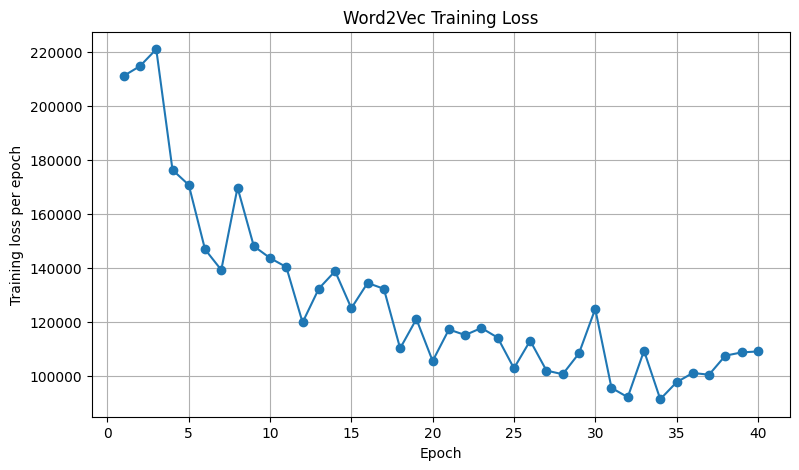

In [ ]:
"""
Step 6 (Hyperparameter tuning; Longest-step Warning!):
First, go back to the baseline models you made in Step 2 and identify the “optimal” number
of iterations separately for wikitext_small and wikitext_large, leaving the rest of
hyperparameters to their default values as they were in Step 2. What does “optimal” mean?
There is no single correct answer; the objective is to avoid overfitting and not wait too long.
Note: Use the EpochLossLogger class we have written for you as a callback function to
track the training loss. Check the example provided in the Colab notebook for details on how
to use it.
"""
import matplotlib.pyplot as plt

small_loss_logger = EpochLossLogger()

model_small_loss = Word2Vec(
    sentences=processed_small,
    vector_size=50,
    window=5,
    min_count=5,
    workers=8,
    epochs=40,
    sg=0,
    seed=42,
    compute_loss=True,
    callbacks=[small_loss_logger]
)

small_window_correlation, small_window_coverage = evaluate_model(
    model_small_loss,
    wordsim_data
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(small_loss_logger.epoch_losses) + 1),
    small_loss_logger.epoch_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("Word2Vec Training Loss")
plt.grid(True)

plt.show()

In [ ]:
"""
Optimal Small Model Epoch Count Finding: 30 epochs




Epochs = 10:

Epoch 01 | epoch loss = 205197.77 | cumulative loss = 205197.77
Epoch 02 | epoch loss = 198138.02 | cumulative loss = 403335.78
Epoch 03 | epoch loss = 188423.59 | cumulative loss = 591759.38
Epoch 04 | epoch loss = 182401.56 | cumulative loss = 774160.94
Epoch 05 | epoch loss = 159203.44 | cumulative loss = 933364.38
Epoch 06 | epoch loss = 167062.38 | cumulative loss = 1100426.75
Epoch 07 | epoch loss = 162712.12 | cumulative loss = 1263138.88
Epoch 08 | epoch loss = 146815.38 | cumulative loss = 1409954.25
Epoch 09 | epoch loss = 158504.25 | cumulative loss = 1568458.50
Epoch 10 | epoch loss = 158298.38 | cumulative loss = 1726756.88
Total pairs: 353
Evaluated pairs: 261
Missing pairs: 92
Spearman correlation: 0.1929
P-value: 0.0017444307224699213
Coverage: 73.94 %



Epochs = 20:

Epoch 01 | epoch loss = 210887.34 | cumulative loss = 210887.34
Epoch 02 | epoch loss = 177784.25 | cumulative loss = 388671.59
Epoch 03 | epoch loss = 202210.53 | cumulative loss = 590882.12
Epoch 04 | epoch loss = 159050.94 | cumulative loss = 749933.06
Epoch 05 | epoch loss = 174187.81 | cumulative loss = 924120.88
Epoch 06 | epoch loss = 196683.12 | cumulative loss = 1120804.00
Epoch 07 | epoch loss = 156473.62 | cumulative loss = 1277277.62
Epoch 08 | epoch loss = 157391.00 | cumulative loss = 1434668.62
Epoch 09 | epoch loss = 137079.62 | cumulative loss = 1571748.25
Epoch 10 | epoch loss = 145793.00 | cumulative loss = 1717541.25
Epoch 11 | epoch loss = 141116.88 | cumulative loss = 1858658.12
Epoch 12 | epoch loss = 127932.50 | cumulative loss = 1986590.62
Epoch 13 | epoch loss = 138680.62 | cumulative loss = 2125271.25
Epoch 14 | epoch loss = 134685.75 | cumulative loss = 2259957.00
Epoch 15 | epoch loss = 132797.25 | cumulative loss = 2392754.25
Epoch 16 | epoch loss = 117091.50 | cumulative loss = 2509845.75
Epoch 17 | epoch loss = 141278.25 | cumulative loss = 2651124.00
Epoch 18 | epoch loss = 115378.25 | cumulative loss = 2766502.25
Epoch 19 | epoch loss = 116232.50 | cumulative loss = 2882734.75
Epoch 20 | epoch loss = 126212.00 | cumulative loss = 3008946.75
Total pairs: 353
Evaluated pairs: 261
Missing pairs: 92
Spearman correlation: 0.3288
P-value: 5.373131113980707e-08
Coverage: 73.94 %



Epochs = 30:

Epoch 01 | epoch loss = 235437.48 | cumulative loss = 235437.48
Epoch 02 | epoch loss = 195493.45 | cumulative loss = 430930.94
Epoch 03 | epoch loss = 186483.75 | cumulative loss = 617414.69
Epoch 04 | epoch loss = 175137.06 | cumulative loss = 792551.75
Epoch 05 | epoch loss = 152933.06 | cumulative loss = 945484.81
Epoch 06 | epoch loss = 145806.69 | cumulative loss = 1091291.50
Epoch 07 | epoch loss = 169045.88 | cumulative loss = 1260337.38
Epoch 08 | epoch loss = 133812.62 | cumulative loss = 1394150.00
Epoch 09 | epoch loss = 159629.88 | cumulative loss = 1553779.88
Epoch 10 | epoch loss = 131577.88 | cumulative loss = 1685357.75
Epoch 11 | epoch loss = 131158.12 | cumulative loss = 1816515.88
Epoch 12 | epoch loss = 134771.25 | cumulative loss = 1951287.12
Epoch 13 | epoch loss = 122041.38 | cumulative loss = 2073328.50
Epoch 14 | epoch loss = 118215.25 | cumulative loss = 2191543.75
Epoch 15 | epoch loss = 128595.50 | cumulative loss = 2320139.25
Epoch 16 | epoch loss = 138556.75 | cumulative loss = 2458696.00
Epoch 17 | epoch loss = 122508.50 | cumulative loss = 2581204.50
Epoch 18 | epoch loss = 110547.75 | cumulative loss = 2691752.25
Epoch 19 | epoch loss = 129322.25 | cumulative loss = 2821074.50
Epoch 20 | epoch loss = 106416.75 | cumulative loss = 2927491.25
Epoch 21 | epoch loss = 115961.50 | cumulative loss = 3043452.75
Epoch 22 | epoch loss = 106761.00 | cumulative loss = 3150213.75
Epoch 23 | epoch loss = 116760.75 | cumulative loss = 3266974.50
Epoch 24 | epoch loss = 113890.75 | cumulative loss = 3380865.25
Epoch 25 | epoch loss = 117751.75 | cumulative loss = 3498617.00
Epoch 26 | epoch loss = 117357.00 | cumulative loss = 3615974.00
Epoch 27 | epoch loss = 127058.00 | cumulative loss = 3743032.00
Epoch 28 | epoch loss = 113390.50 | cumulative loss = 3856422.50
Epoch 29 | epoch loss = 102335.00 | cumulative loss = 3958757.50
Epoch 30 | epoch loss = 100254.50 | cumulative loss = 4059012.00
Total pairs: 353
Evaluated pairs: 261
Missing pairs: 92
Spearman correlation: 0.3672
P-value: 9.383334436727518e-10
Coverage: 73.94 %


Epochs = 40:

Epoch 01 | epoch loss = 211201.41 | cumulative loss = 211201.41
Epoch 02 | epoch loss = 214823.59 | cumulative loss = 426025.00
Epoch 03 | epoch loss = 221084.94 | cumulative loss = 647109.94
Epoch 04 | epoch loss = 176350.94 | cumulative loss = 823460.88
Epoch 05 | epoch loss = 170789.69 | cumulative loss = 994250.56
Epoch 06 | epoch loss = 146907.19 | cumulative loss = 1141157.75
Epoch 07 | epoch loss = 139271.12 | cumulative loss = 1280428.88
Epoch 08 | epoch loss = 169802.88 | cumulative loss = 1450231.75
Epoch 09 | epoch loss = 148099.38 | cumulative loss = 1598331.12
Epoch 10 | epoch loss = 143681.12 | cumulative loss = 1742012.25
Epoch 11 | epoch loss = 140346.75 | cumulative loss = 1882359.00
Epoch 12 | epoch loss = 119816.62 | cumulative loss = 2002175.62
Epoch 13 | epoch loss = 132359.88 | cumulative loss = 2134535.50
Epoch 14 | epoch loss = 138814.00 | cumulative loss = 2273349.50
Epoch 15 | epoch loss = 125099.50 | cumulative loss = 2398449.00
Epoch 16 | epoch loss = 134460.50 | cumulative loss = 2532909.50
Epoch 17 | epoch loss = 132281.25 | cumulative loss = 2665190.75
Epoch 18 | epoch loss = 110214.25 | cumulative loss = 2775405.00
Epoch 19 | epoch loss = 121063.50 | cumulative loss = 2896468.50
Epoch 20 | epoch loss = 105523.25 | cumulative loss = 3001991.75
Epoch 21 | epoch loss = 117207.25 | cumulative loss = 3119199.00
Epoch 22 | epoch loss = 115146.75 | cumulative loss = 3234345.75
Epoch 23 | epoch loss = 117763.75 | cumulative loss = 3352109.50
Epoch 24 | epoch loss = 114178.75 | cumulative loss = 3466288.25
Epoch 25 | epoch loss = 102825.50 | cumulative loss = 3569113.75
Epoch 26 | epoch loss = 113058.75 | cumulative loss = 3682172.50
Epoch 27 | epoch loss = 101974.50 | cumulative loss = 3784147.00
Epoch 28 | epoch loss = 100619.50 | cumulative loss = 3884766.50
Epoch 29 | epoch loss = 108353.75 | cumulative loss = 3993120.25
Epoch 30 | epoch loss = 124845.50 | cumulative loss = 4117965.75
Epoch 31 | epoch loss = 95555.25 | cumulative loss = 4213521.00
Epoch 32 | epoch loss = 92109.00 | cumulative loss = 4305630.00
Epoch 33 | epoch loss = 109331.50 | cumulative loss = 4414961.50
Epoch 34 | epoch loss = 91358.00 | cumulative loss = 4506319.50
Epoch 35 | epoch loss = 97642.00 | cumulative loss = 4603961.50
Epoch 36 | epoch loss = 101086.00 | cumulative loss = 4705047.50
Epoch 37 | epoch loss = 100442.50 | cumulative loss = 4805490.00
Epoch 38 | epoch loss = 107501.00 | cumulative loss = 4912991.00
Epoch 39 | epoch loss = 108704.50 | cumulative loss = 5021695.50
Epoch 40 | epoch loss = 109070.50 | cumulative loss = 5130766.00
Total pairs: 353
Evaluated pairs: 261
Missing pairs: 92
Spearman correlation: 0.3599
P-value: 2.1095594434659876e-09
Coverage: 73.94 %






Experiment:

Experiment 1:

model_small_10epochs = Word2Vec(
    sentences=processed_small,
    vector_size=50,
    window=5,
    min_count=5,
    workers=8,
    epochs=10,
    sg=0,
    seed=42,
    compute_loss=True,
    callbacks=[small_loss_logger]
)



Experiment 2:





"""

Epoch 01 | epoch loss = 30320884.00 | cumulative loss = 30320884.00
Epoch 02 | epoch loss = 16004980.00 | cumulative loss = 46325864.00
Epoch 03 | epoch loss = 14408928.00 | cumulative loss = 60734792.00
Epoch 04 | epoch loss = 7799056.00 | cumulative loss = 68533848.00
Epoch 05 | epoch loss = 2560592.00 | cumulative loss = 71094440.00
Epoch 06 | epoch loss = 2542432.00 | cumulative loss = 73636872.00
Epoch 07 | epoch loss = 2493800.00 | cumulative loss = 76130672.00
Epoch 08 | epoch loss = 2460888.00 | cumulative loss = 78591560.00
Epoch 09 | epoch loss = 2378352.00 | cumulative loss = 80969912.00
Epoch 10 | epoch loss = 2274912.00 | cumulative loss = 83244824.00
Epoch 11 | epoch loss = 2136616.00 | cumulative loss = 85381440.00
Epoch 12 | epoch loss = 2013504.00 | cumulative loss = 87394944.00
Epoch 13 | epoch loss = 1885184.00 | cumulative loss = 89280128.00
Epoch 14 | epoch loss = 1745312.00 | cumulative loss = 91025440.00
Epoch 15 | epoch loss = 1594240.00 | cumulative loss = 9261

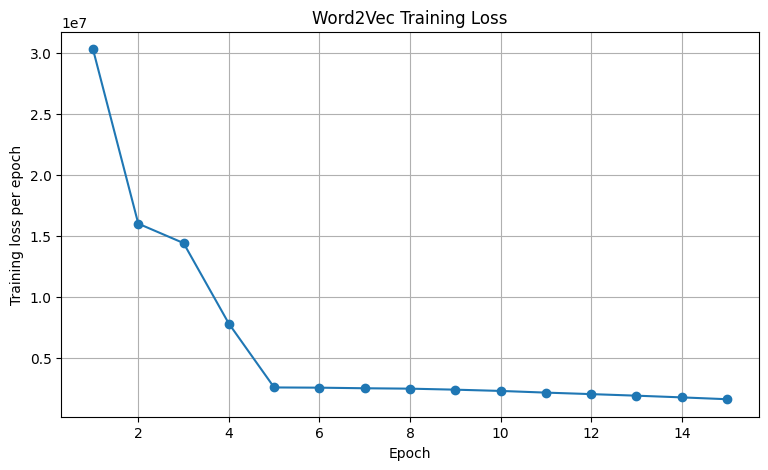

In [ ]:
"""
Large Model
"""

large_loss_logger = EpochLossLogger()

model_large_loss = Word2Vec(
    sentences=large_corpus,
    vector_size=50,
    window=5,
    min_count=5,
    workers=8,
    epochs=15,
    sg=0,
    seed=42,
    compute_loss=True,
    callbacks=[large_loss_logger]
)

large_loss_correlation, large_loss_coverage = evaluate_model(
    model_large_loss,
    wordsim_data
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(large_loss_logger.epoch_losses) + 1),
    large_loss_logger.epoch_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("Word2Vec Training Loss")
plt.grid(True)

plt.show()

In [ ]:
"""
Optimal Large Model Epoch Count Finding: 5 epochs




Epochs = 10:

Epoch 01 | epoch loss = 30735678.00 | cumulative loss = 30735678.00
Epoch 02 | epoch loss = 16181386.00 | cumulative loss = 46917064.00
Epoch 03 | epoch loss = 14940080.00 | cumulative loss = 61857144.00
Epoch 04 | epoch loss = 6869512.00 | cumulative loss = 68726656.00
Epoch 05 | epoch loss = 2422432.00 | cumulative loss = 71149088.00
Epoch 06 | epoch loss = 2398184.00 | cumulative loss = 73547272.00
Epoch 07 | epoch loss = 2243920.00 | cumulative loss = 75791192.00
Epoch 08 | epoch loss = 2033792.00 | cumulative loss = 77824984.00
Epoch 09 | epoch loss = 1809096.00 | cumulative loss = 79634080.00
Epoch 10 | epoch loss = 1590552.00 | cumulative loss = 81224632.00
Total pairs: 353
Evaluated pairs: 353
Missing pairs: 0
Spearman correlation: 0.6242
P-value: 1.6200477158956797e-39
Coverage: 100.0 %



Epochs = 15:

Epoch 01 | epoch loss = 30320884.00 | cumulative loss = 30320884.00
Epoch 02 | epoch loss = 16004980.00 | cumulative loss = 46325864.00
Epoch 03 | epoch loss = 14408928.00 | cumulative loss = 60734792.00
Epoch 04 | epoch loss = 7799056.00 | cumulative loss = 68533848.00
Epoch 05 | epoch loss = 2560592.00 | cumulative loss = 71094440.00
Epoch 06 | epoch loss = 2542432.00 | cumulative loss = 73636872.00
Epoch 07 | epoch loss = 2493800.00 | cumulative loss = 76130672.00
Epoch 08 | epoch loss = 2460888.00 | cumulative loss = 78591560.00
Epoch 09 | epoch loss = 2378352.00 | cumulative loss = 80969912.00
Epoch 10 | epoch loss = 2274912.00 | cumulative loss = 83244824.00
Epoch 11 | epoch loss = 2136616.00 | cumulative loss = 85381440.00
Epoch 12 | epoch loss = 2013504.00 | cumulative loss = 87394944.00
Epoch 13 | epoch loss = 1885184.00 | cumulative loss = 89280128.00
Epoch 14 | epoch loss = 1745312.00 | cumulative loss = 91025440.00
Epoch 15 | epoch loss = 1594240.00 | cumulative loss = 92619680.00
Total pairs: 353
Evaluated pairs: 353
Missing pairs: 0
Spearman correlation: 0.6214
P-value: 4.427098641801503e-39
Coverage: 100.0 %




"""

Model Experimenting



Small model 30 epochs, 100 vector size, 5 window size, 5 min count
Epoch 01 | epoch loss = 219238.02 | cumulative loss = 219238.02
Epoch 02 | epoch loss = 198053.83 | cumulative loss = 417291.84
Epoch 03 | epoch loss = 187349.47 | cumulative loss = 604641.31
Epoch 04 | epoch loss = 176913.88 | cumulative loss = 781555.19
Epoch 05 | epoch loss = 168982.94 | cumulative loss = 950538.12
Epoch 06 | epoch loss = 166117.38 | cumulative loss = 1116655.50
Epoch 07 | epoch loss = 158072.88 | cumulative loss = 1274728.38
Epoch 08 | epoch loss = 136751.75 | cumulative loss = 1411480.12
Epoch 09 | epoch loss = 162073.75 | cumulative loss = 1573553.88
Epoch 10 | epoch loss = 140943.62 | cumulative loss = 1714497.50
Epoch 11 | epoch loss = 138381.12 | cumulative loss = 1852878.62
Epoch 12 | epoch loss = 122827.75 | cumulative loss = 1975706.38
Epoch 13 | epoch loss = 119144.25 | cumulative loss = 2094850.62
Epoch 14 | epoch loss = 123212.88 | cumulative loss = 2218063.50
Epoch 15 | epoch loss = 12

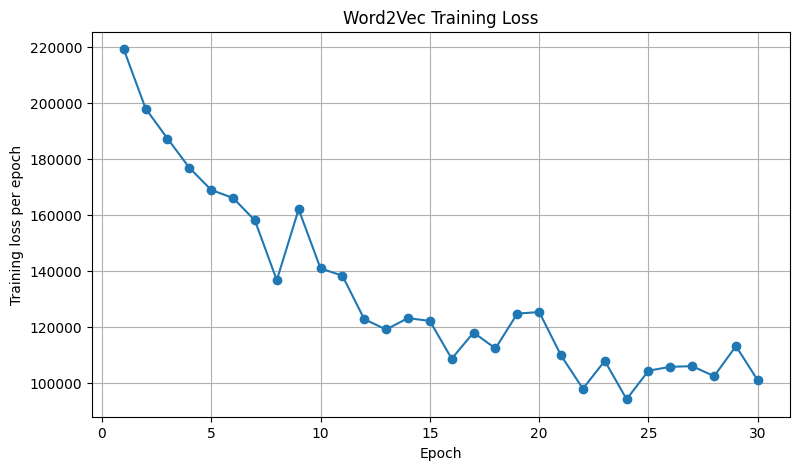



Small model 30 epochs, 50 vector size, 10 window size, 5 min count
Epoch 01 | epoch loss = 222360.75 | cumulative loss = 222360.75
Epoch 02 | epoch loss = 189501.47 | cumulative loss = 411862.22
Epoch 03 | epoch loss = 176481.91 | cumulative loss = 588344.12
Epoch 04 | epoch loss = 174960.38 | cumulative loss = 763304.50
Epoch 05 | epoch loss = 164053.69 | cumulative loss = 927358.19
Epoch 06 | epoch loss = 160265.19 | cumulative loss = 1087623.38
Epoch 07 | epoch loss = 157364.62 | cumulative loss = 1244988.00
Epoch 08 | epoch loss = 147575.62 | cumulative loss = 1392563.62
Epoch 09 | epoch loss = 145693.25 | cumulative loss = 1538256.88
Epoch 10 | epoch loss = 139196.62 | cumulative loss = 1677453.50
Epoch 11 | epoch loss = 153545.62 | cumulative loss = 1830999.12
Epoch 12 | epoch loss = 134364.38 | cumulative loss = 1965363.50
Epoch 13 | epoch loss = 121507.75 | cumulative loss = 2086871.25
Epoch 14 | epoch loss = 118020.75 | cumulative loss = 2204892.00
Epoch 15 | epoch loss = 13

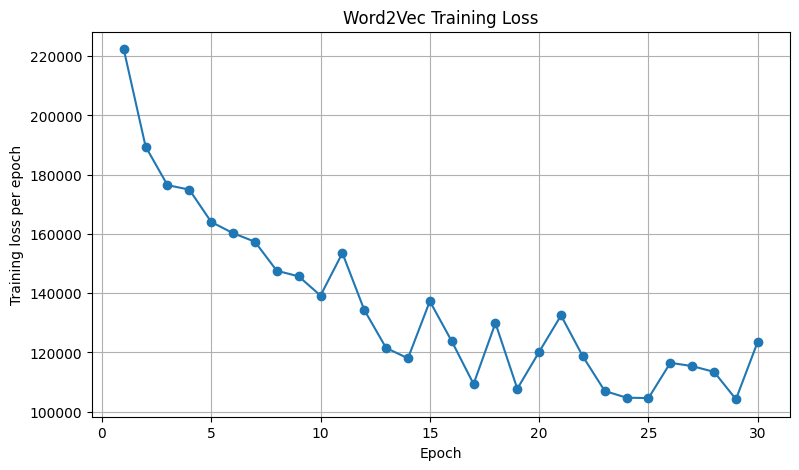



Small model 30 epochs, 50 vector size, 5 window size, 2 min count
Epoch 01 | epoch loss = 288210.47 | cumulative loss = 288210.47
Epoch 02 | epoch loss = 213255.25 | cumulative loss = 501465.72
Epoch 03 | epoch loss = 200404.97 | cumulative loss = 701870.69
Epoch 04 | epoch loss = 191708.75 | cumulative loss = 893579.44
Epoch 05 | epoch loss = 184137.19 | cumulative loss = 1077716.62
Epoch 06 | epoch loss = 177876.12 | cumulative loss = 1255592.75
Epoch 07 | epoch loss = 170321.62 | cumulative loss = 1425914.38
Epoch 08 | epoch loss = 179679.62 | cumulative loss = 1605594.00
Epoch 09 | epoch loss = 145059.25 | cumulative loss = 1750653.25
Epoch 10 | epoch loss = 152969.88 | cumulative loss = 1903623.12
Epoch 11 | epoch loss = 152741.62 | cumulative loss = 2056364.75
Epoch 12 | epoch loss = 144297.50 | cumulative loss = 2200662.25
Epoch 13 | epoch loss = 125352.00 | cumulative loss = 2326014.25
Epoch 14 | epoch loss = 134013.75 | cumulative loss = 2460028.00
Epoch 15 | epoch loss = 13

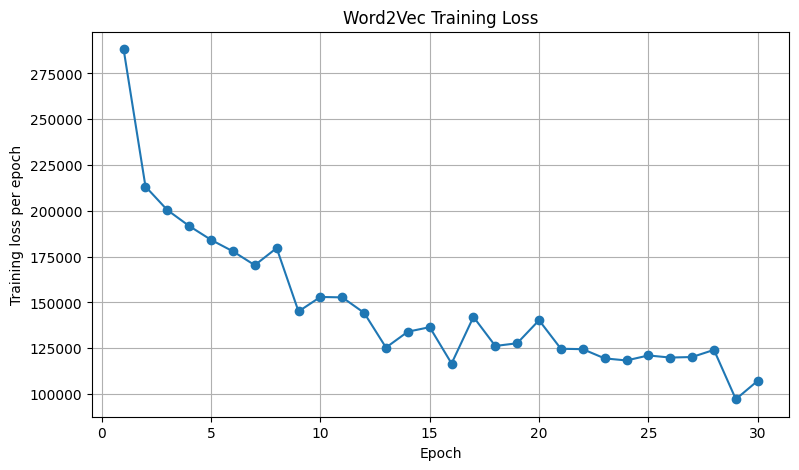

In [24]:
import matplotlib.pyplot as plt

print("\n\nSmall model 30 epochs, 100 vector size, 5 window size, 5 min count")
small_loss_logger = EpochLossLogger()

model_small_loss = Word2Vec(
    sentences=processed_small,
    vector_size=100,
    window=5,
    min_count=5,
    workers=8,
    epochs=30,
    sg=0,
    seed=42,
    compute_loss=True,
    callbacks=[small_loss_logger]
)

small_window_correlation, small_window_coverage = evaluate_model(
    model_small_loss,
    wordsim_data
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(small_loss_logger.epoch_losses) + 1),
    small_loss_logger.epoch_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("Word2Vec Training Loss")
plt.grid(True)

plt.show()









print("\n\nSmall model 30 epochs, 50 vector size, 10 window size, 5 min count")
small_loss_logger = EpochLossLogger()

model_small_loss = Word2Vec(
    sentences=processed_small,
    vector_size=50,
    window=10,
    min_count=5,
    workers=8,
    epochs=30,
    sg=0,
    seed=42,
    compute_loss=True,
    callbacks=[small_loss_logger]
)

small_window_correlation, small_window_coverage = evaluate_model(
    model_small_loss,
    wordsim_data
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(small_loss_logger.epoch_losses) + 1),
    small_loss_logger.epoch_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("Word2Vec Training Loss")
plt.grid(True)

plt.show()








print("\n\nSmall model 30 epochs, 50 vector size, 5 window size, 2 min count")
small_loss_logger = EpochLossLogger()

model_small_loss = Word2Vec(
    sentences=processed_small,
    vector_size=50,
    window=5,
    min_count=2,
    workers=8,
    epochs=30,
    sg=0,
    seed=42,
    compute_loss=True,
    callbacks=[small_loss_logger]
)

small_window_correlation, small_window_coverage = evaluate_model(
    model_small_loss,
    wordsim_data
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(small_loss_logger.epoch_losses) + 1),
    small_loss_logger.epoch_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("Word2Vec Training Loss")
plt.grid(True)

plt.show()

In [ ]:
"""
Summary:

Small model 30 epochs, 100 vector size, 5 window size, 5 min count
Epoch 01 | epoch loss = 219238.02 | cumulative loss = 219238.02
Epoch 02 | epoch loss = 198053.83 | cumulative loss = 417291.84
Epoch 03 | epoch loss = 187349.47 | cumulative loss = 604641.31
Epoch 04 | epoch loss = 176913.88 | cumulative loss = 781555.19
Epoch 05 | epoch loss = 168982.94 | cumulative loss = 950538.12
Epoch 06 | epoch loss = 166117.38 | cumulative loss = 1116655.50
Epoch 07 | epoch loss = 158072.88 | cumulative loss = 1274728.38
Epoch 08 | epoch loss = 136751.75 | cumulative loss = 1411480.12
Epoch 09 | epoch loss = 162073.75 | cumulative loss = 1573553.88
Epoch 10 | epoch loss = 140943.62 | cumulative loss = 1714497.50
Epoch 11 | epoch loss = 138381.12 | cumulative loss = 1852878.62
Epoch 12 | epoch loss = 122827.75 | cumulative loss = 1975706.38
Epoch 13 | epoch loss = 119144.25 | cumulative loss = 2094850.62
Epoch 14 | epoch loss = 123212.88 | cumulative loss = 2218063.50
Epoch 15 | epoch loss = 122203.75 | cumulative loss = 2340267.25
Epoch 16 | epoch loss = 108706.75 | cumulative loss = 2448974.00
Epoch 17 | epoch loss = 118064.50 | cumulative loss = 2567038.50
Epoch 18 | epoch loss = 112381.25 | cumulative loss = 2679419.75
Epoch 19 | epoch loss = 124811.50 | cumulative loss = 2804231.25
Epoch 20 | epoch loss = 125390.25 | cumulative loss = 2929621.50
Epoch 21 | epoch loss = 109863.50 | cumulative loss = 3039485.00
Epoch 22 | epoch loss = 97997.25 | cumulative loss = 3137482.25
Epoch 23 | epoch loss = 107937.50 | cumulative loss = 3245419.75
Epoch 24 | epoch loss = 94244.25 | cumulative loss = 3339664.00
Epoch 25 | epoch loss = 104436.25 | cumulative loss = 3444100.25
Epoch 26 | epoch loss = 105823.75 | cumulative loss = 3549924.00
Epoch 27 | epoch loss = 106049.50 | cumulative loss = 3655973.50
Epoch 28 | epoch loss = 102476.25 | cumulative loss = 3758449.75
Epoch 29 | epoch loss = 113206.00 | cumulative loss = 3871655.75
Epoch 30 | epoch loss = 100953.75 | cumulative loss = 3972609.50
Total pairs: 353
Evaluated pairs: 261
Missing pairs: 92
Spearman correlation: 0.3944
P-value: 3.8058997164785026e-11
Coverage: 73.94 %









Small model 30 epochs, 50 vector size, 10 window size, 5 min count
Epoch 01 | epoch loss = 222360.75 | cumulative loss = 222360.75
Epoch 02 | epoch loss = 189501.47 | cumulative loss = 411862.22
Epoch 03 | epoch loss = 176481.91 | cumulative loss = 588344.12
Epoch 04 | epoch loss = 174960.38 | cumulative loss = 763304.50
Epoch 05 | epoch loss = 164053.69 | cumulative loss = 927358.19
Epoch 06 | epoch loss = 160265.19 | cumulative loss = 1087623.38
Epoch 07 | epoch loss = 157364.62 | cumulative loss = 1244988.00
Epoch 08 | epoch loss = 147575.62 | cumulative loss = 1392563.62
Epoch 09 | epoch loss = 145693.25 | cumulative loss = 1538256.88
Epoch 10 | epoch loss = 139196.62 | cumulative loss = 1677453.50
Epoch 11 | epoch loss = 153545.62 | cumulative loss = 1830999.12
Epoch 12 | epoch loss = 134364.38 | cumulative loss = 1965363.50
Epoch 13 | epoch loss = 121507.75 | cumulative loss = 2086871.25
Epoch 14 | epoch loss = 118020.75 | cumulative loss = 2204892.00
Epoch 15 | epoch loss = 137286.25 | cumulative loss = 2342178.25
Epoch 16 | epoch loss = 123810.50 | cumulative loss = 2465988.75
Epoch 17 | epoch loss = 109336.50 | cumulative loss = 2575325.25
Epoch 18 | epoch loss = 129917.25 | cumulative loss = 2705242.50
Epoch 19 | epoch loss = 107739.25 | cumulative loss = 2812981.75
Epoch 20 | epoch loss = 120196.75 | cumulative loss = 2933178.50
Epoch 21 | epoch loss = 132478.50 | cumulative loss = 3065657.00
Epoch 22 | epoch loss = 118630.25 | cumulative loss = 3184287.25
Epoch 23 | epoch loss = 106982.75 | cumulative loss = 3291270.00
Epoch 24 | epoch loss = 104714.50 | cumulative loss = 3395984.50
Epoch 25 | epoch loss = 104601.75 | cumulative loss = 3500586.25
Epoch 26 | epoch loss = 116493.00 | cumulative loss = 3617079.25
Epoch 27 | epoch loss = 115386.75 | cumulative loss = 3732466.00
Epoch 28 | epoch loss = 113427.00 | cumulative loss = 3845893.00
Epoch 29 | epoch loss = 104205.75 | cumulative loss = 3950098.75
Epoch 30 | epoch loss = 123673.00 | cumulative loss = 4073771.75
Total pairs: 353
Evaluated pairs: 261
Missing pairs: 92
Spearman correlation: 0.4027
P-value: 1.349182679986582e-11
Coverage: 73.94 %

















Small model 30 epochs, 50 vector size, 5 window size, 2 min count
Epoch 01 | epoch loss = 288210.47 | cumulative loss = 288210.47
Epoch 02 | epoch loss = 213255.25 | cumulative loss = 501465.72
Epoch 03 | epoch loss = 200404.97 | cumulative loss = 701870.69
Epoch 04 | epoch loss = 191708.75 | cumulative loss = 893579.44
Epoch 05 | epoch loss = 184137.19 | cumulative loss = 1077716.62
Epoch 06 | epoch loss = 177876.12 | cumulative loss = 1255592.75
Epoch 07 | epoch loss = 170321.62 | cumulative loss = 1425914.38
Epoch 08 | epoch loss = 179679.62 | cumulative loss = 1605594.00
Epoch 09 | epoch loss = 145059.25 | cumulative loss = 1750653.25
Epoch 10 | epoch loss = 152969.88 | cumulative loss = 1903623.12
Epoch 11 | epoch loss = 152741.62 | cumulative loss = 2056364.75
Epoch 12 | epoch loss = 144297.50 | cumulative loss = 2200662.25
Epoch 13 | epoch loss = 125352.00 | cumulative loss = 2326014.25
Epoch 14 | epoch loss = 134013.75 | cumulative loss = 2460028.00
Epoch 15 | epoch loss = 136480.75 | cumulative loss = 2596508.75
Epoch 16 | epoch loss = 116633.75 | cumulative loss = 2713142.50
Epoch 17 | epoch loss = 142087.00 | cumulative loss = 2855229.50
Epoch 18 | epoch loss = 126218.25 | cumulative loss = 2981447.75
Epoch 19 | epoch loss = 127699.75 | cumulative loss = 3109147.50
Epoch 20 | epoch loss = 140267.00 | cumulative loss = 3249414.50
Epoch 21 | epoch loss = 124684.00 | cumulative loss = 3374098.50
Epoch 22 | epoch loss = 124468.50 | cumulative loss = 3498567.00
Epoch 23 | epoch loss = 119438.75 | cumulative loss = 3618005.75
Epoch 24 | epoch loss = 118312.00 | cumulative loss = 3736317.75
Epoch 25 | epoch loss = 121038.25 | cumulative loss = 3857356.00
Epoch 26 | epoch loss = 119892.00 | cumulative loss = 3977248.00
Epoch 27 | epoch loss = 120186.50 | cumulative loss = 4097434.50
Epoch 28 | epoch loss = 124080.00 | cumulative loss = 4221514.50
Epoch 29 | epoch loss = 97144.00 | cumulative loss = 4318658.50
Epoch 30 | epoch loss = 107196.50 | cumulative loss = 4425855.00
Total pairs: 353
Evaluated pairs: 310
Missing pairs: 43
Spearman correlation: 0.333
P-value: 1.8256020581382762e-09
Coverage: 87.82 %

"""



Large model 5 epochs, 100 vector size, 5 window size, 5 min count
Epoch 01 | epoch loss = 30920380.00 | cumulative loss = 30920380.00
Epoch 02 | epoch loss = 16439584.00 | cumulative loss = 47359964.00
Epoch 03 | epoch loss = 14576124.00 | cumulative loss = 61936088.00
Epoch 04 | epoch loss = 6611584.00 | cumulative loss = 68547672.00
Epoch 05 | epoch loss = 1960536.00 | cumulative loss = 70508208.00
Total pairs: 353
Evaluated pairs: 353
Missing pairs: 0
Spearman correlation: 0.6461
P-value: 4.2714611193858846e-43
Coverage: 100.0 %


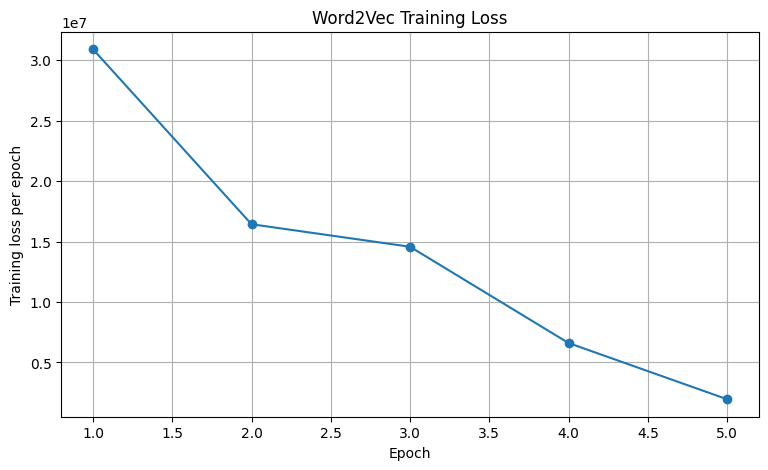



Large model 5 epochs, 50 vector size, 10 window size, 5 min count
Epoch 01 | epoch loss = 27213788.00 | cumulative loss = 27213788.00
Epoch 02 | epoch loss = 15618620.00 | cumulative loss = 42832408.00
Epoch 03 | epoch loss = 12746300.00 | cumulative loss = 55578708.00
Epoch 04 | epoch loss = 11605652.00 | cumulative loss = 67184360.00
Epoch 05 | epoch loss = 1529488.00 | cumulative loss = 68713848.00
Total pairs: 353
Evaluated pairs: 353
Missing pairs: 0
Spearman correlation: 0.6553
P-value: 1.1289234708011263e-44
Coverage: 100.0 %


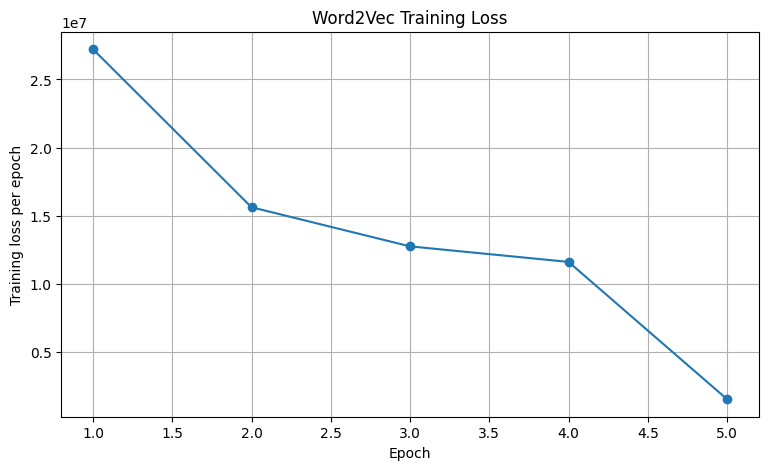



Large model 5 epochs, 50 vector size, 5 window size, 2 min count
Epoch 01 | epoch loss = 30025298.00 | cumulative loss = 30025298.00
Epoch 02 | epoch loss = 15707674.00 | cumulative loss = 45732972.00
Epoch 03 | epoch loss = 13780628.00 | cumulative loss = 59513600.00
Epoch 04 | epoch loss = 8468992.00 | cumulative loss = 67982592.00
Epoch 05 | epoch loss = 1769072.00 | cumulative loss = 69751664.00
Total pairs: 353
Evaluated pairs: 353
Missing pairs: 0
Spearman correlation: 0.6201
P-value: 6.923986355655949e-39
Coverage: 100.0 %


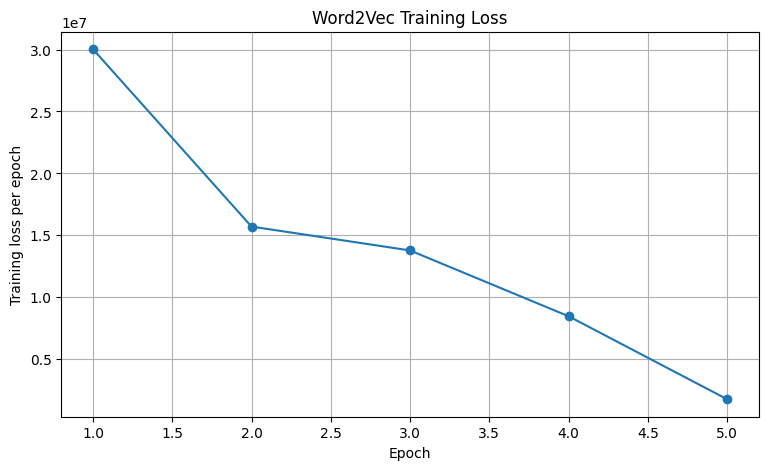

In [25]:


print("\n\nLarge model 5 epochs, 100 vector size, 5 window size, 5 min count")
large_loss_logger = EpochLossLogger()

model_large_loss = Word2Vec(
    sentences=large_corpus,
    vector_size=100,
    window=5,
    min_count=5,
    workers=8,
    epochs=5,
    sg=0,
    seed=42,
    compute_loss=True,
    callbacks=[large_loss_logger]
)

large_loss_correlation, large_loss_coverage = evaluate_model(
    model_large_loss,
    wordsim_data
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(large_loss_logger.epoch_losses) + 1),
    large_loss_logger.epoch_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("Word2Vec Training Loss")
plt.grid(True)

plt.show()






print("\n\nLarge model 5 epochs, 50 vector size, 10 window size, 5 min count")
large_loss_logger = EpochLossLogger()

model_large_loss = Word2Vec(
    sentences=large_corpus,
    vector_size=50,
    window=10,
    min_count=5,
    workers=8,
    epochs=5,
    sg=0,
    seed=42,
    compute_loss=True,
    callbacks=[large_loss_logger]
)

large_loss_correlation, large_loss_coverage = evaluate_model(
    model_large_loss,
    wordsim_data
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(large_loss_logger.epoch_losses) + 1),
    large_loss_logger.epoch_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("Word2Vec Training Loss")
plt.grid(True)

plt.show()






print("\n\nLarge model 5 epochs, 50 vector size, 5 window size, 2 min count")
large_loss_logger = EpochLossLogger()

model_large_loss = Word2Vec(
    sentences=large_corpus,
    vector_size=50,
    window=5,
    min_count=2,
    workers=8,
    epochs=5,
    sg=0,
    seed=42,
    compute_loss=True,
    callbacks=[large_loss_logger]
)

large_loss_correlation, large_loss_coverage = evaluate_model(
    model_large_loss,
    wordsim_data
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(large_loss_logger.epoch_losses) + 1),
    large_loss_logger.epoch_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training loss per epoch")
plt.title("Word2Vec Training Loss")
plt.grid(True)

plt.show()

In [ ]:
"""
Summary:

Large model 5 epochs, 100 vector size, 5 window size, 5 min count
Epoch 01 | epoch loss = 30920380.00 | cumulative loss = 30920380.00
Epoch 02 | epoch loss = 16439584.00 | cumulative loss = 47359964.00
Epoch 03 | epoch loss = 14576124.00 | cumulative loss = 61936088.00
Epoch 04 | epoch loss = 6611584.00 | cumulative loss = 68547672.00
Epoch 05 | epoch loss = 1960536.00 | cumulative loss = 70508208.00
Total pairs: 353
Evaluated pairs: 353
Missing pairs: 0
Spearman correlation: 0.6461
P-value: 4.2714611193858846e-43
Coverage: 100.0 %






Large model 5 epochs, 50 vector size, 10 window size, 5 min count
Epoch 01 | epoch loss = 27213788.00 | cumulative loss = 27213788.00
Epoch 02 | epoch loss = 15618620.00 | cumulative loss = 42832408.00
Epoch 03 | epoch loss = 12746300.00 | cumulative loss = 55578708.00
Epoch 04 | epoch loss = 11605652.00 | cumulative loss = 67184360.00
Epoch 05 | epoch loss = 1529488.00 | cumulative loss = 68713848.00
Total pairs: 353
Evaluated pairs: 353
Missing pairs: 0
Spearman correlation: 0.6553
P-value: 1.1289234708011263e-44
Coverage: 100.0 %






Large model 5 epochs, 50 vector size, 5 window size, 2 min count
Epoch 01 | epoch loss = 30025298.00 | cumulative loss = 30025298.00
Epoch 02 | epoch loss = 15707674.00 | cumulative loss = 45732972.00
Epoch 03 | epoch loss = 13780628.00 | cumulative loss = 59513600.00
Epoch 04 | epoch loss = 8468992.00 | cumulative loss = 67982592.00
Epoch 05 | epoch loss = 1769072.00 | cumulative loss = 69751664.00
Total pairs: 353
Evaluated pairs: 353
Missing pairs: 0
Spearman correlation: 0.6201
P-value: 6.923986355655949e-39
Coverage: 100.0 %

"""